# Stochastic calculus in SigAlg I: a preview of the Itô lemma

Stochastic calculus is often introduced as calculus with randomness added, but randomness is not what distinguishes it. What sets it apart is that it handles processes whose paths are far too irregular for classical calculus, such as Brownian motion, whose paths are nowhere differentiable. For such processes the Fundamental Theorem of Calculus, as usually stated, fails. Equivalently, the chain rule $df(X_t) = f'(X_t)\,dX_t$ fails, since it is the differential form of the same statement. The repair is the *Itô lemma*, which adds a single correction term built from the second derivative of the function and the *quadratic variation* of the process.

This tutorial is a preview of that result. We first build an integral against a stochastic process and check that the classical Fundamental Theorem holds when the paths are smooth. We then replace the smooth paths with Brownian ones and watch the theorem fail. Finally, we show that the Itô correction restores the equality, and that the correction is differentiable even though the paths are not. Each statement is tested numerically in SigAlg by computing both sides of the identity path by path, so you can see the correction at work.

One of SigAlg's main use cases is quantitative finance, and it is there that the failure of the chain rule has practical consequences. Many contracts have values that are functions of an underlying asset price. A *derivative* is a contract whose payoff is a function $f(S_T)$ of the price $S_T$ of an underlying asset at a future time $T$; we saw examples of such payoff functions in a previous SigAlg tutorial. A common model for the underlying price is *geometric Brownian motion*, governed by the stochastic differential equation
$$
dS_t = \mu S_t\,dt + \sigma S_t\,dW_t,
$$
where $W_t$ is a standard Brownian motion. To understand how the derivative's value moves over time, we need the dynamics of $f(S_t)$, which is exactly what the chain rule would give us if $S_t$ were smooth. But because $S_t$ is driven by a Brownian motion, we need the Itô lemma instead.

Future tutorials will cover the full time-dependent version of the Itô lemma, as well as more applications to finance.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jmyers7/sigalg/blob/main/docs/notebooks/stochastic-calc-1.ipynb)

In [1]:
# If running in Google Colab, uncomment the line below and run this cell first.
# Also, for Mac+Chrome users, beware of a known bug with LaTeX rendering in Colab: https://github.com/googlecolab/colabtools/issues/3192

# !pip install sigalg

## Classical calculus

Let $f(x)$ be a real-valued function of a real variable $x$. As we learned in our first course in calculus, given two numbers $x$ and $\Delta x$, the increment in the function may be approximated using the derivative of $f$, provided that it exists:
$$
f(x+\Delta x) - f(x) \approx f'(x)\, \Delta x. \tag{1}
$$
Generally, the smaller (in magnitude) $\Delta x$, the better the approximation, and in the limit as $\Delta x \to 0$ we obtain an equality
$$
df(x) = f'(x) \, dx. \tag{2}
$$
Intuitively, we think of the *differentials* $df(x)$ and $dx$ as "infinitesimals": They are vanishingly small numbers that $f(x+\Delta x) - f(x)$ and $\Delta x$ "pass through" before they reach $0$ as $\Delta x \to 0$.

(Technical sidenote: The reader who demands more than just "intuition" for what infinitesimals actually *are* should reach for a book on *nonstandard analysis*. Alternatively, if geometry rather than analysis is your focus, differentials are rigorously constructed using not much more than basic linear algebra in the theory of *differential forms*, and purely algebraic differentials called *Kähler differentials* appear in *algebraic geometry*. The point is this: There are quite a few different constructions of differentials and infinitesimals that capture various aspects of the classical "really small number" intuition. Depending on your use case, some constructions might be more useful than others. However, this applies only to "smooth" differentials, or at least differentiable ones. In contrast, the "stochastic" differentials that we will see below really are just formal figments of our imagination.)

An application of the Fundamental Theorem of Calculus over an interval $[x_1,x_2]$ gives
$$
f(x_2) - f(x_1) = \int_{x_1}^{x_2} f'(x) \, dx. \tag{3}
$$
Or, alternatively, one may obtain this equality by "formally integrating" both sides of (2) to get
$$
\int_{x_1}^{x_2} df(x) = \int_{x_1}^{x_2} f'(x) \, dx, \tag{4}
$$
where the integral on the left is a Riemann-Stieltjes integral with $\int_{x_1}^{x_2} df(x) = f(x_2)-f(x_1)$ trivially. This alternate method does not give us (3) for free, however, since (4) is actually a non-trivial result in the theory of Riemann-Stieltjes integrals. (For more on this theory, a good reference is Apostol's handy book *Mathematical Analysis*.)

Another method for increasing the accuracy of the approximation (1) is to bring in the second-order term from the Taylor expansion of $f$, provided that $f$ is twice-differentiable:
$$
f(x+\Delta x) - f(x) \approx f'(x)\, \Delta x + \frac{1}{2}f''(x) \, \Delta x^2.
$$
As with the first-order approximation (1), this one also improves as $\Delta x \to 0$. However, for twice-differentiable functions like $f$, the second-order term is superfluous if what we are after is the differential $df(x)$, since (2) shows that it may be obtained from the first order piece $f'(x) \, dx$ alone.

Remember that last sentence, for it marks the departure from classical to stochastic calculus, to which we now turn.

## Breaking classical calculus: a first look at stochastic calculus

If *stochastic* is a synonym for *random*, then the first thing you should know about stochastic calculus is that it is more than just "random calculus". Indeed, the Lebesgue theory already extends classical integral calculus from deterministic variables to random ones. Rather, the distinctive way in which stochastic calculus extends the classical theory lies not so much in randomness, but in the extreme non-differentiability of the types of objects that it deals with.

To illustrate this point, let's take a look at a simple example in which classical methods still work. Suppose that I give you a random cubic polynomial. By this, I don't mean that I somehow randomly select a *single* cubic polynomial and hand it to you, but rather I give you a *probability distribution* over a collection of cubic polynomials. Formally, we suppose that we have a stochastic process $X_t$, indexed by $t\in [0,\infty)$, with the property that the trajectory $t\mapsto X_t(\omega)$ is a cubic polynomial for each sample point $\omega$.

An example in SigAlg is given in the next code block. It consists of three distinct cubic polynomials, each with equal probability of being realized.

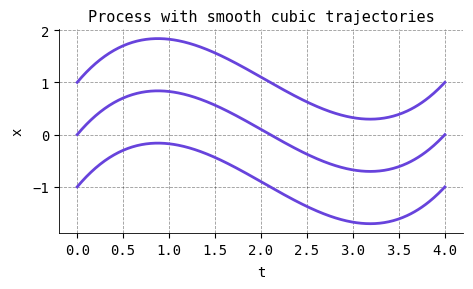

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import sigalg as sa

sa.style.set_style()

n_trajectories = 3
Delta_t = 0.01


def cubics(t: np.ndarray) -> np.ndarray:  # noqa: D103
    polys = [
        lambda t_i, a=a: 0.25 * t_i * (t_i - 2.1) * (t_i - 4) + a
        for a in np.linspace(-1, 1, n_trajectories)
    ]
    return np.array([p(t_i) for p, t_i in zip(polys, t)])


T = sa.Time.continuous(start=0, stop=4, dt=Delta_t)

X = sa.StochasticProcess.from_time(
    T, n_trajectories=n_trajectories
).apply_to_components(cubics, name="X")

_, ax = plt.subplots(figsize=(5, 3))
X.plot_trajectories(ax, y_label="x", x_label="t", colors=[sa.style.purple])
ax.set_title("Process with smooth cubic trajectories")
plt.tight_layout()
plt.show()

Our goal is to construct an integral for the stochastic process $X_t$ and to demonstrate that a form of the classical Fundamental Theorem of Calculus holds. You will see that essentially no new ideas are needed.

We return to the first-order approximation in the previous section that started it all:
$$
f(x_2) - f(x_1) \approx f'(x_1)(x_2-x_1),
$$
where $f(x)$ is a differentiable function of the real variable $x$. Of course, there is nothing to prevent us from replacing the determinsic variables $x_1$ and $x_2$ with random ones. Let's choose two random variables from our cubic stochastic process:
$$
f(X_{t_2}) - f(X_{t_1}) \approx f'(X_{t_1})(X_{t_2} - X_{t_1}).
$$
The left- and right-hand sides of this approximation are random variables, and intuition suggests that the approximation should be good (in some sense) as long as $t_1$ and $t_2$ are near each other since the trajectories of $X_t$ are smooth.

Suppose that we fix an interval $[a,b]$ and a partition
$$
a = t_0 < t_1 < \cdots< t_n = b.
$$
Over each subinterval $[t_k, t_{k+1}]$, we have an approximation of the above form:
$$
f(X_{t_{k+1}}) - f(X_{t_k}) \approx f'(X_{t_k})(X_{t_{k+1}} - X_{t_k}).
$$
If we sum both sides, the left-hand side telescopes and we get
$$
f(X_b) - f(X_a) \approx \sum_{k=0}^{n-1} f'(X_{t_k})(X_{t_{k+1}} - X_{t_k}). \tag{5}
$$
Now, the right-hand side looks a lot like a finite approximation to a Riemann-Stieltjes integral, but again you must be careful to remember that it is actually a sum of random variables, not real numbers. Nevertheless, we are tempted to refine the partition of $[a,b]$, letting the number of subintervals go to $\infty$. Provided that the right-hand side converges (in some mode) to a random variable, it is tempting to call that random variable an *integral*. If it exists and is unique, we shall write it as
$$
\int_a^b f'(X_t) \, dX_t.
$$
Actually, we may as well let the upper limit $b$ vary, replacing it with the variable $t$ and choosing another dummy variable for the integration, in which case we get a stochastic process
$$
\int_a^t f'(X_u) \, dX_u
$$
indexed by $t$. If all this works, then we might be tempted to hypothesize a new Fundamental Theorem, that looks a whole lot like the classical one:
$$
f(X_t) - f(X_a) = \int_a^t f'(X_u) \, dX_u. \tag{6}
$$

The next code block investigates this hypothesized Fundamental Theorem, using our smooth cubic process from above and the function $f(x) = e^x$.

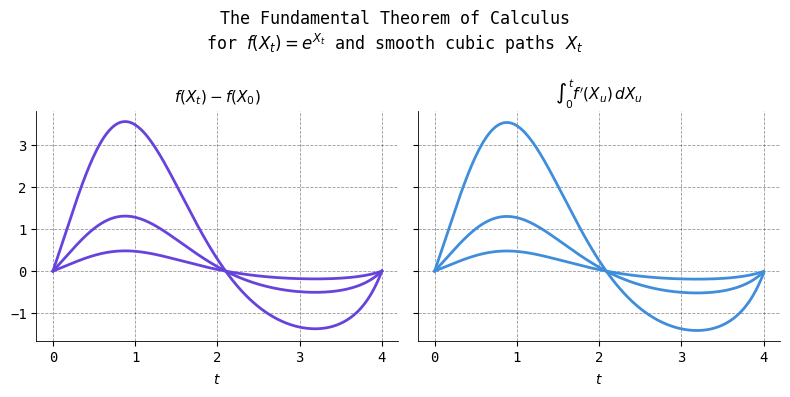

In [3]:
fig, axes = plt.subplots(ncols=2, sharex=True, sharey=True, figsize=(8, 4))

ito_integral = sa.ProcessTransforms.ito_integral  # this will be explained below

increment = ito_integral(integrator=np.exp(X))
classical_term = ito_integral(np.exp(X), X)

increment.plot_trajectories(axes[0], colors=[sa.style.purple])
classical_term.plot_trajectories(axes[1], colors=[sa.style.blue])

axes[0].set_title(r"$f(X_t) - f(X_0)$")
axes[1].set_title(r"$\int_0^t f'(X_u) \, dX_u$")
axes[0].set_xlabel("$t$")
axes[1].set_xlabel("$t$")

fig.suptitle(
    "The Fundamental Theorem of Calculus\nfor $f(X_t) = e^{X_t}$ and smooth cubic paths $X_t$"
)
plt.tight_layout()
plt.show()

By visual inspection, it appears that our Fundamental Theorem (6) holds, and indeed it *can* be proven rigorously. One just needs to take care to construct the integral precisely, including a description of exactly what *convergence* means. (Roughly, one builds approximations to the integral using so-called *simple processes*, and then takes an appropriate $L^2$-limit.) Setting aside the mathematical subtleties of convergence and existence of this new integral — called an *Itô integral* — at least the reader can see that nothing here involves any new ideas beyond classical ones. 

The reader notices the `ito_integral` method in the code block from the `ProcessTransforms` class. In SigAlg, all instances of `StochasticProcess` are discrete-time, constructed from instances of `Time` that specify a partition
$$
a = t_0 < t_1 < \cdots < t_n = b
$$
of an interval $[a,b]$. If $X_t$ and $Z_t$ are two instances of `StochasticProcess` constructed from the same `Time` instance, then we *define* the Itô integral as
$$
\int_a^{t_k} X_u \, dZ_u = \sum_{j=1}^{k} X_{t_{j-1}} (Z_{t_{j}} - Z_{t_{j-1}})
$$
for each $k=1, 2, \ldots, n$, and set $\int_a^a X_u \, dZ_u=0$ when $k=0$. The process $X_t$ is called the *integrand*, while $Z_t$ is called the *integrator*. So, in the code block where we used `ito_integral` to construct an increment of the process, we were using the equality
$$
X_t - X_a = \int_a^t dX_u,
$$
which holds for all processes $X_t$.

The adequacy of the classical theory is due to the smoothness of our cubic process. But the true power of stochastic calculus comes when this nice process is replaced with Brownian motions and other diffusion processes. The reader may recall from a previous SigAlg tutorial that Brownian paths are highly irregular, being non-differentiable everywhere (almost surely). In the next code cell, we plot some simulations drawn from a standard Brownian motion $W_t$ as a reminder.

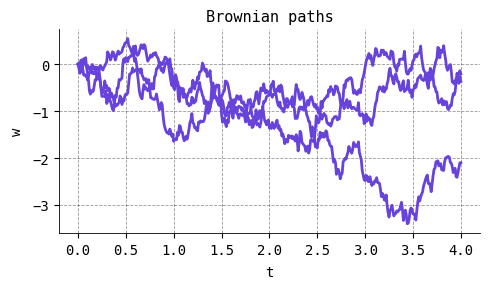

In [4]:
W = sa.BrownianMotion.generate(
    n_trajectories=n_trajectories, index=T, name="W", random_state=42
)

_, ax = plt.subplots(figsize=(5, 3))
W.plot_trajectories(ax, y_label="w", x_label="t", colors=[sa.style.purple])
ax.set_title("Brownian paths")
plt.tight_layout()
plt.show()

Now, let's inspect the classical Fundamental Theorem of Calculus when the smooth cubic trajectories above are replaced with Brownian ones.

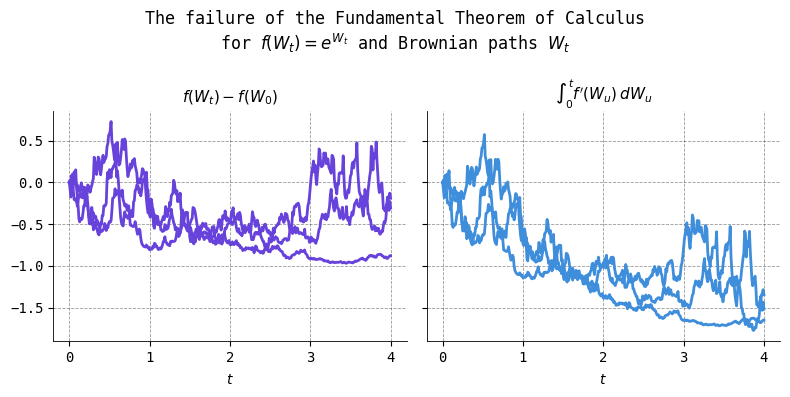

In [5]:
fig, axes = plt.subplots(ncols=2, sharex=True, sharey=True, figsize=(8, 4))

increment = ito_integral(integrator=np.exp(W))
classical_term = ito_integral(np.exp(W), W)

increment.plot_trajectories(axes[0], colors=[sa.style.purple])
classical_term.plot_trajectories(axes[1], colors=[sa.style.blue])

axes[0].set_title(r"$f(W_t) - f(W_0)$")
axes[1].set_title(r"$\int_0^t f'(W_u) \, dW_u$")
axes[0].set_xlabel("$t$")
axes[1].set_xlabel("$t$")

fig.suptitle(
    "The failure of the Fundamental Theorem of Calculus\nfor $f(W_t) = e^{W_t}$ and Brownian paths $W_t$"
)
plt.tight_layout()
plt.show()

The theorem evidently fails. It appears that
$$
f(W_t) - f(W_0) \neq \int_0^t f'(W_u) \, dW_u
$$
when $W_t$ is a Brownian motion.

So we wonder: Is there a "correction term" that we may add to the right-hand side of the Fundamental Theorem, to recover an equality? The answer is *Yes*.

## Fixing the Fundamental Theorem: the Itô correction

Given our discussion so far, the origin of the Itô correction is no surprise. It appears simply as the degree-$2$ piece of the Taylor approximation:
$$
f(X_{t_{k+1}}) - f(X_{t_k}) \approx f'(X_{t_k})(X_{t_{k+1}} - X_{t_k}) + \frac{1}{2}f''(X_{t_k})(X_{t_{k+1}} - X_{t_k})^2,
$$
where
$$
a = t_0 < t_1 < \cdots < t_n = b
$$
is a partition of the interval $[a,b]$. Summing both sides, we get
$$
f(X_b) - f(X_a) \approx \sum_{k=0}^{n-1}f'(X_{t_k})  (X_{t_{k+1}} - X_{t_k}) + \frac{1}{2} \sum_{k=0}^{n-1}f''(X_{t_k})(X_{t_{k+1}} - X_{t_k})^2. \tag{7}
$$
The central insight offered by stochastic calculus is not that inclusion of the degree-$2$ term improves the approximation. Rather, the insight is that this degree-$2$ term is actually a degree-$1$ term in a certain sense, and including it recovers the Fundamental Theorem.

While the first sum on the right of (7) is a discrete approximation to the Itô integral (in SigAlg, it *is* an Itô integral), the second term does not appear to be related to an integral at first glance. However, at each of the partition points $t_k$ with $k\geq 1$, suppose that we define
$$
[X]_{t_k} = \sum_{j=0}^{k-1} (X_{t_{j+1}} - X_{t_j})^2. \tag{8}
$$
When $k=0$, we put $[X]_{t_0}=0$. In this way, we obtain a discrete-time stochastic process $[X]_t$, indexed over the partition $\{t_0,t_1,\ldots,t_n\}$, and (7) may be rewritten as
$$
f(X_b) - f(X_a) \approx \sum_{k=0}^{n-1}f'(X_t)  (X_{t_{k+1}} - X_{t_k}) + \frac{1}{2} \sum_{k=0}^{n-1}f''(X_{t_k})([X]_{t_{k+1}} - [X]_{t_k}).
$$
Now *both* of the sums on the right-hand side of the approximation appear as discrete approximations to Itô integrals, and we are tempted to write
$$
f(X_t) - f(X_a) = \int_a^t f'(X_u) \, dX_u + \frac{1}{2} \int_a^t f''(X_u) \, d[X]_u \tag{9}
$$
in the limit, where we've replaced $b$ with the variable $t$ and chosen a different dummy variable for integration. This is then a (hypothesized) equation of stochastic processes. The second Itô integral is called the *Itô correction*.

Using SigAlg, we visually inspect the validity of (9), using both our process with smooth cubic paths and a Brownian motion.

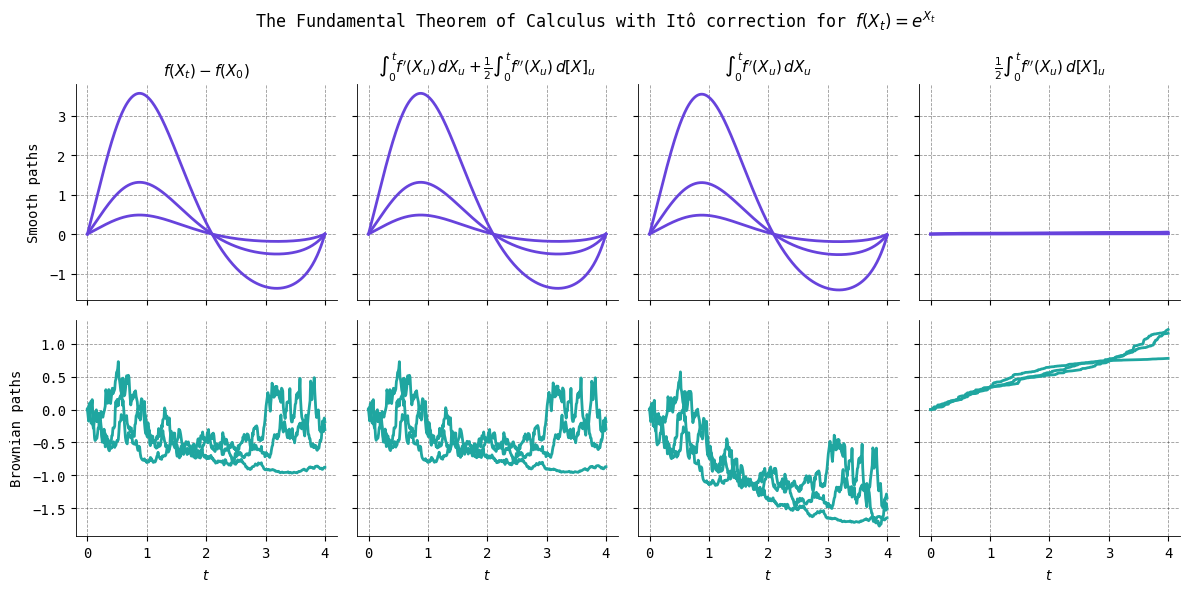

In [6]:
fig, axes = plt.subplots(ncols=4, nrows=2, figsize=(12, 6), sharey="row", sharex=True)

quad_var = sa.ProcessTransforms.quad_var

col_titles = [
    r"$f(X_t)-f(X_0)$",
    r"$\int_0^t f'(X_u) \, dX_u+\frac{1}{2} \int_0^t f''(X_u) \, d[X]_u$",
    r"$\int_0^t f'(X_u) \, dX_u$",
    r"$\frac{1}{2} \int_0^t f''(X_u) \, d[X]_u$",
]
row_labels = ["Smooth paths", "Brownian paths"]

for i, (process, color) in enumerate(zip([X, W], [sa.style.purple, sa.style.teal])):
    row_ax = axes[i]

    if i == 0:
        for ax, title in zip(row_ax, col_titles):
            ax.set_title(title)

    if i == 1:
        for ax in row_ax:
            ax.set_xlabel("$t$")

    row_ax[0].set_ylabel(row_labels[i])

    increment = ito_integral(integrator=np.exp(process))
    classical_term = ito_integral(np.exp(process), process)
    ito_correction = (1 / 2) * ito_integral(np.exp(process), quad_var(process))

    increment.plot_trajectories(row_ax[0], colors=[color])
    (classical_term + ito_correction).plot_trajectories(row_ax[1], colors=[color])
    classical_term.plot_trajectories(row_ax[2], colors=[color])
    ito_correction.plot_trajectories(row_ax[3], colors=[color])

fig.suptitle(r"The Fundamental Theorem of Calculus with Itô correction for $f(X_t) = e^{X_t}$")
plt.tight_layout()
plt.show()

The left column shows the increment processes for both the smooth paths and the Brownian ones; the second column displays the right-hand side of Fundamental Theorem with Itô correction; the third and fourth columns show the classical and Itô terms in the Fundamental Theorem. For the smooth paths, the Itô correction vanishes, as it should, since we know that the classical Fundamental Theorem already holds. But for the Brownian paths, the Itô correction is *not* negligible and its inclusion appears indeed to "correct" the failure of the classical Fundamental Theorem. In addition, the Itô correction for Brownian paths is very regular. We will return to this regularity below.

Inspired by the apparent validity of the new Fundamental Theorem (9), we are tempted to write
$$
df(X_t) = f'(X_t) \, dX_t + \frac{1}{2} f''(X_t) \, d[X]_t, \tag{10}
$$
which should be compared to the expression (2) that we encountered in elementary calculus. Differentials are linear, degree-$1$ objects. Interestingly, stochastic calculus shows that the degree-$2$ term of a Taylor expansion contributes an extra degree-$1$ term to the classical differential. (You should understand that the differentials in this expression are assigned no independent meaning; this equation is merely a convenient notational shorthand for the mathematically meaningful statement (9).)

The formal equation (10) is a version of *Itô's lemma* in which the function $f$ does not itself explicitly depend on time $t$. The version that is often stated in introductory books on the subject takes $f$ of the form $f(t, X_t)$, and allows $X_t$ to be a general diffusion process. We will discuss this more general form of the lemma in a future tutorial.

## Quadratic variation

To end this tutorial, we return to the discrete-time process
$$
[X]_{t_k} = \sum_{j=0}^{k-1} (X_{t_{j+1}} - X_{t_j})^2
$$
appearing as the integrator in Itô's correction. This is called a *quadratic variation*, relative to the given partition. In the general theory, the *absolute* quadratic variation is obtained (intuitively) from these discrete-time processes as the maximal step size of the partition goes to $0$. (One must again be precise about what *convergence* means.) In SigAlg, however, in which *all* processes are discrete-time, this definition *is* the absolute quadratic variation, and it is computed via the `quad_var` method from the `ProcessTransforms` class, as was shown in the code block above.

We plot the quadratic variation process of our Brownian motion from above.

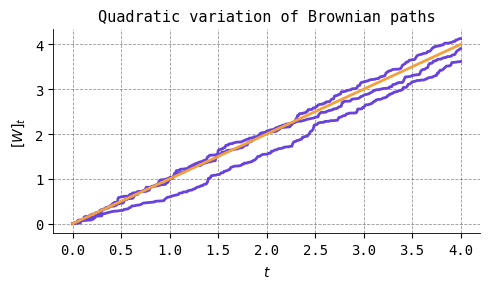

In [7]:
_, ax = plt.subplots(figsize=(5, 3))

quad_var(W).plot_trajectories(ax, colors=[sa.style.purple])
ax.plot(T, T, color=sa.style.amber)

ax.set_title("Quadratic variation of Brownian paths")
ax.set_ylabel(r"$[W]_t$")
ax.set_xlabel(r"$t$")
plt.tight_layout()
plt.show()

The small sample size of only three trajectories notwithstanding, it appears — and is indeed true — that the quadratic variation process of the Brownian motion is simply $t$ itself: $[W]_t \approx t$ with equality in the limit. This simple expression is actually quite remarkable, considering how irregular Brownian paths are.

This has implications for the Itô correction: We have
$$
\frac{1}{2} \int_0^t f''(W_u) \, d[W]_u = \frac{1}{2} \int_0^t f''(W_u) \, du,
$$
where the integral on the right is a simple Riemann integral computed path by path. Since Brownian paths are continuous, this integral certainly exists, and the classical Fundamental Theorem tells us that the derivative
$$
\frac{d}{dt} \left( \frac{1}{2} \int_0^t f''(W_u) \, du \right)
$$
also exists (and is equal to $\frac{1}{2}f''(W_t)$). Thus, the Itô correction is differentiable!

How about the quadratic variation of our smooth cubic process? It is plotted below for three different step sizes.

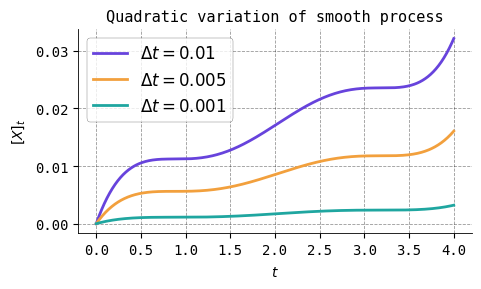

In [8]:
_, ax = plt.subplots(figsize=(5, 3))

Delta_ts = [0.01, 0.005, 0.001]

for Delta_t in Delta_ts:
    T = sa.Time.continuous(start=0, stop=4, dt=Delta_t)
    X = sa.StochasticProcess.from_time(T, n_trajectories=1).apply_to_components(
        cubics, name="X"
    )

    quad_var(X).plot_trajectories(ax, label=rf"$\Delta t={Delta_t}$")

ax.set_title("Quadratic variation of smooth process")
ax.set_ylabel(r"$[X]_t$")
ax.set_xlabel(r"$t$")
ax.legend()
plt.tight_layout()
plt.show()

In contrast to the quadratic variation process of Brownian motion, it appears that the quadratic variation of the smooth paths vanishes as $\Delta t \to 0$. This is indeed true.

So, we may reframe the lessons discovered in this tutorial as follows: The Itô correction is not needed in classical calculus since processes with smooth trajectories have vanishing quadratic variation. In this case, the classical Fundamental Theorem of Calculus holds. On the other hand, even though Brownian trajectories are highly irregular, they still have a finite and tractable quadratic variation, and so we may "fix" the Fundamental Theorem by including a (smooth and differentiable) Itô correction term built from the second derivative of the function.